In [9]:
%%time
dataset_name = "W30_comb"
df_list = "BES_Panel"

%matplotlib inline 
%run BES_header.py {dataset_name} {df_list}

global BES_label_list, BES_df_list

Toggle code

var_type (12866, 13)
old_new_col_names not loaded
CPU times: total: 10.3 s
Wall time: 51.7 s


In [88]:
wave = 1

like_list = list( search(BES_Panel,"like(Con|Lab|LD|Grn|UKIP|SNP|PC)W"+str(wave)).index )
like_list

['likeConW1',
 'likeLabW1',
 'likeLDW1',
 'likeSNPW1',
 'likePCW1',
 'likeUKIPW1',
 'likeGrnW1',
 'likeConW10',
 'likeLabW10',
 'likeLDW10',
 'likeSNPW10',
 'likePCW10',
 'likeUKIPW10',
 'likeGrnW10',
 'likeConW11',
 'likeLabW11',
 'likeLDW11',
 'likeSNPW11',
 'likePCW11',
 'likeUKIPW11',
 'likeGrnW11',
 'likeConW12',
 'likeLabW12',
 'likeLDW12',
 'likeSNPW12',
 'likePCW12',
 'likeUKIPW12',
 'likeGrnW12',
 'likeConW13',
 'likeLabW13',
 'likeLDW13',
 'likeSNPW13',
 'likePCW13',
 'likeUKIPW13',
 'likeGrnW13',
 'likeConW14',
 'likeLabW14',
 'likeLDW14',
 'likeSNPW14',
 'likePCW14',
 'likeUKIPW14',
 'likeGrnW14',
 'likeConW15',
 'likeLabW15',
 'likeLDW15',
 'likeSNPW15',
 'likePCW15',
 'likeUKIPW15',
 'likeGrnW15',
 'likeConW16',
 'likeLabW16',
 'likeLDW16',
 'likeSNPW16',
 'likePCW16',
 'likeUKIPW16',
 'likeGrnW16',
 'likeConW17',
 'likeLabW17',
 'likeLDW17',
 'likeSNPW17',
 'likePCW17',
 'likeUKIPW17',
 'likeGrnW17',
 'likeConW18',
 'likeLabW18',
 'likeLDW18',
 'likeSNPW18',
 'likePCW18'

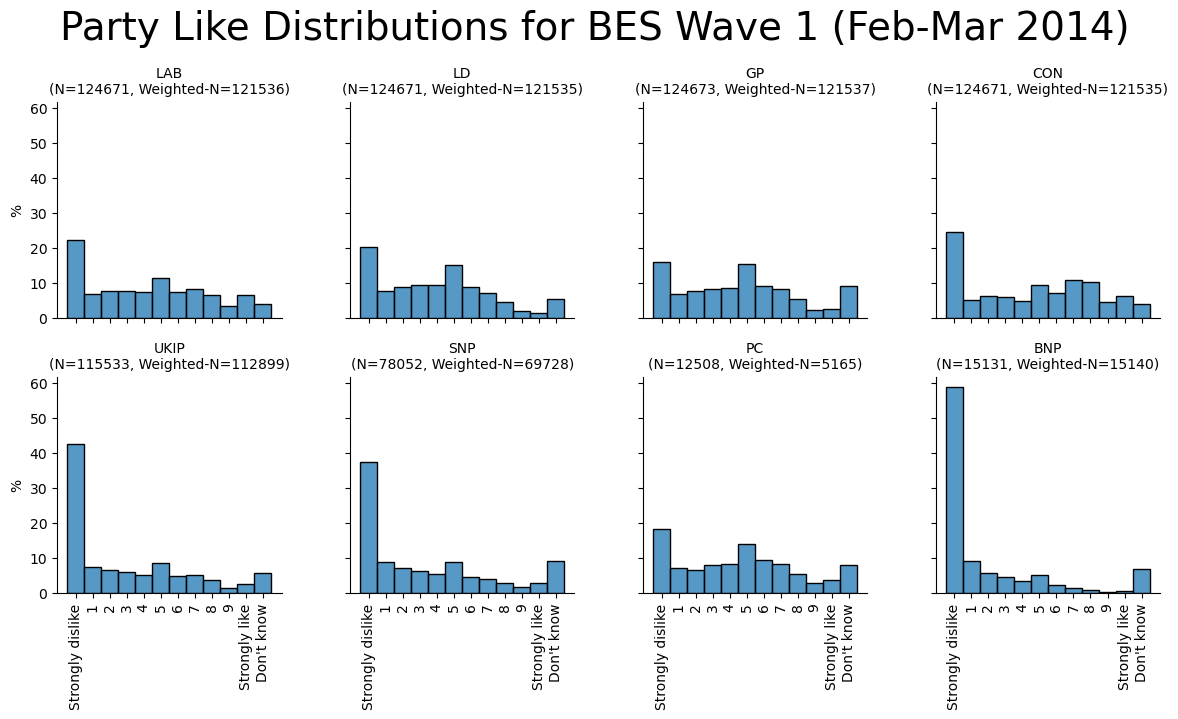

In [91]:
wave = 1

like_list = list( search(BES_Panel,"like(Con|Lab|LD|Grn|UKIP|SNP|PC|BNP)W"+str(wave)).index )
wt_var = search(BES_Panel,"wt_(new|full)_W"+str(wave)+"($|_result)").index[0]

replace_dict = {'Con':"CON", 'Grn':"GP", 'UKIP':"UKIP", 'LD':"LD", 'Lab':"LAB","SNP":"SNP","PC":"PC","BNP":"BNP"}
palette = {"CON":'blue',"LAB":'red',"REFUK":'cyan',"LD":'orange',"GP":'green',"SNP":'yellow',"PC":'olive',"BNP":'black'}


data = BES_Panel[[wt_var]+like_list]
data = data.melt(id_vars = wt_var)
data.columns = ["wt","party","like"]
data["party"] = data["party"].replace(replace_dict)
data["party"] = data["party"].apply(lambda x: x.split("like")[1].split("W")[0]).replace({k+"W"+str(wave):v for k,v in replace_dict.items()})
data=data.dropna()

data["party"] = data["party"].replace(replace_dict).astype('category').cat.reorder_categories(["LAB","LD","GP","CON","UKIP","SNP","PC","BNP"])

sample_size = data.groupby("party").count()["like"]
weighted_sample_size = data.groupby("party")["wt"].sum().round().astype(int)
title_replace_dict = {k: k+"\n(N="+str(sample_size.loc[k])+", Weighted-N="+str(weighted_sample_size.loc[k])+")" for k in sample_size.index}
data["party"] = data["party"].replace(title_replace_dict)

# sns.histplot(data = BES_Panel,x="likeConW29",weights="wt_new_W29_result",stat='percent');
# plt.xticks(rotation=90);

# do we facetgrid

g = sns.FacetGrid(data, col="party",col_wrap=4)
g.map_dataframe(sns.histplot, x="like",weights="wt",stat='percent');
g.fig.suptitle("Party Like Distributions for BES Wave 1 (Feb-Mar 2014)",y=1.07,fontsize="28");
g.set_axis_labels("", "%");
g.set_titles(col_template="{col_name}");
for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)

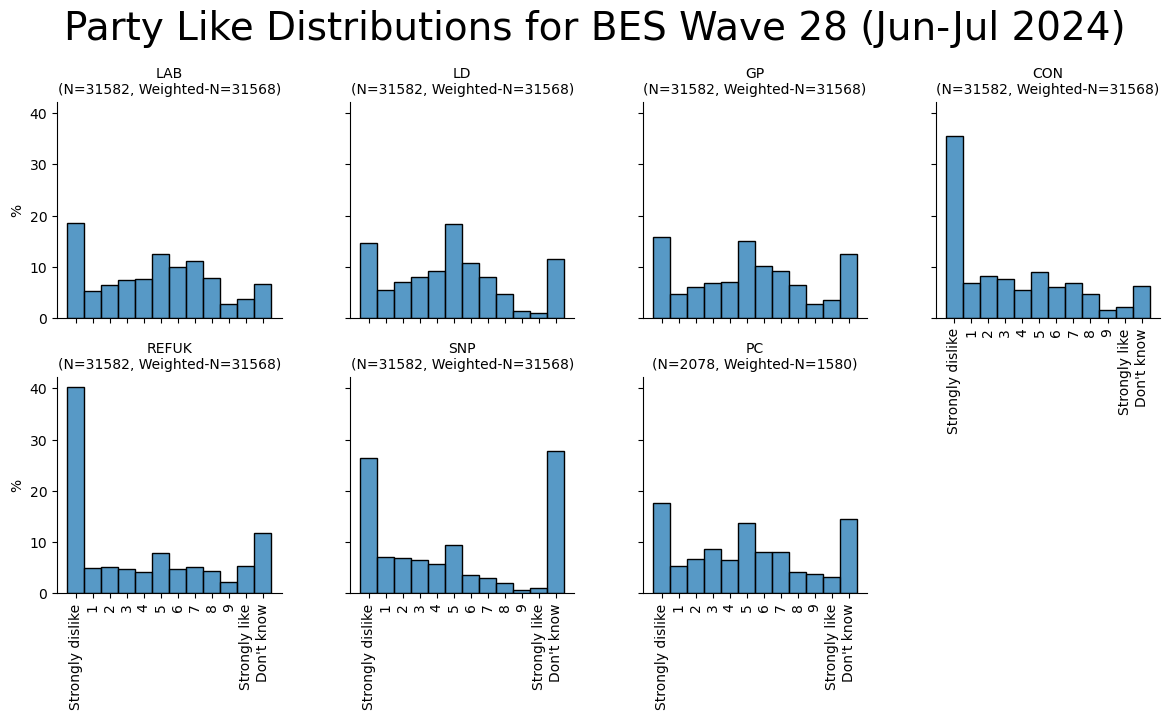

In [215]:
wave = 28
title_text = "Party Like Distributions for BES Wave 28 (Jun-Jul 2024)"

like_list = list( search(BES_Panel,"like(Con|Lab|LD|Grn|BrexitParty|SNP|PC)W"+str(wave)).index )
wt_var = search(BES_Panel,"wt_new_W"+str(wave)+"($|_result)").index[0]

replace_dict = {'Con':"CON", 'Grn':"GP", 'BrexitParty':"REFUK", 'LD':"LD", 'Lab':"LAB","SNP":"SNP","PC":"PC"}
palette = {"CON":'blue',"LAB":'red',"REFUK":'cyan',"LD":'orange',"GP":'green',"SNP":'yellow',"PC":'olive'}


data = BES_Panel[[wt_var]+like_list]
data = data.melt(id_vars = wt_var)
data.columns = ["wt","party","like"]
data["party"] = data["party"].replace(replace_dict)
data["party"] = data["party"].apply(lambda x: x.split("like")[1].split("W")[0]).replace({k+"W"+str(wave):v for k,v in replace_dict.items()})
data=data.dropna()

data["party"] = data["party"].replace(replace_dict).astype('category').cat.reorder_categories(["LAB","LD","GP","CON","REFUK","SNP","PC"])

sample_size = data.groupby("party").count()["like"]
weighted_sample_size = data.groupby("party")["wt"].sum().round().astype(int)
title_replace_dict = {k: k+"\n(N="+str(sample_size.loc[k])+", Weighted-N="+str(weighted_sample_size.loc[k])+")" for k in sample_size.index}
data["party"] = data["party"].replace(title_replace_dict)

# sns.histplot(data = BES_Panel,x="likeConW29",weights="wt_new_W29_result",stat='percent');
# plt.xticks(rotation=90);

# do we facetgrid

g = sns.FacetGrid(data, col="party",col_wrap=4)
g.map_dataframe(sns.histplot, x="like",weights="wt",stat='percent');
g.fig.suptitle(title_text,y=1.07,fontsize="28");
g.set_axis_labels("", "%");
g.set_titles(col_template="{col_name}");
for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)

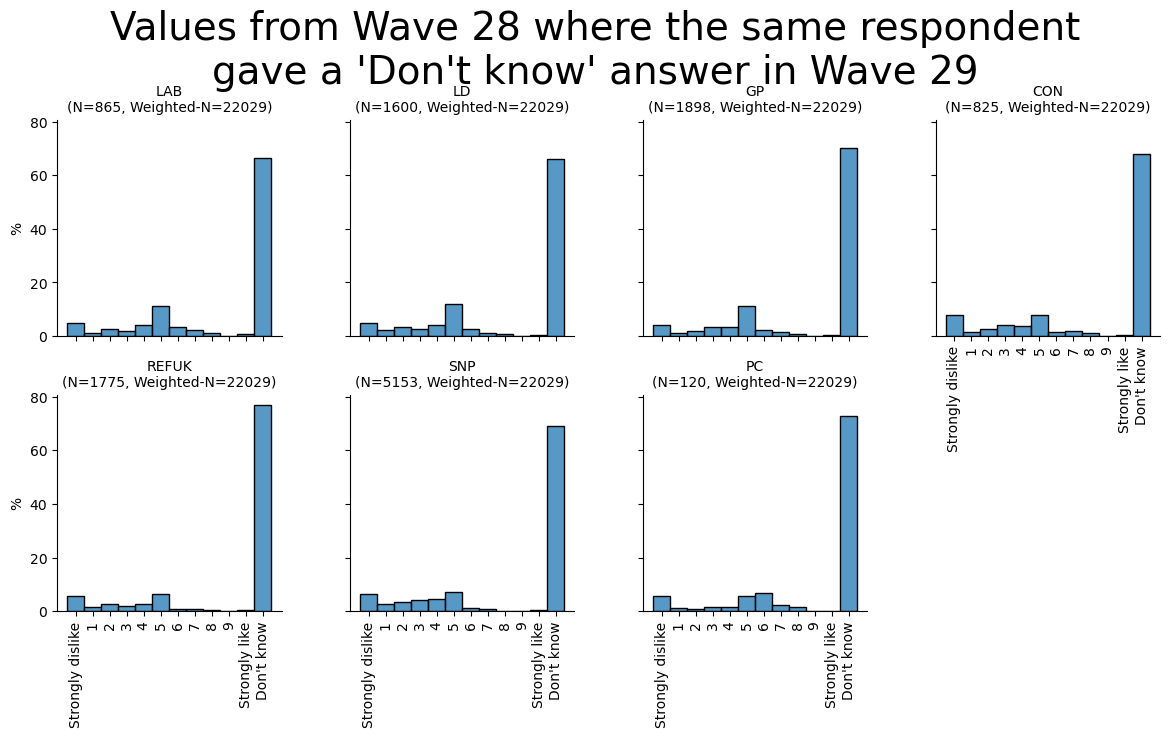

In [214]:
wave = 28

like_list = list( search(BES_Panel,"like(Con|Lab|LD|Grn|BrexitParty|SNP|PC)W"+str(wave)).index )
wt_var = search(BES_Panel,"wt_new_W"+str(wave)+"($|_result)").index[0]

like_list_prior_wave = list( search(BES_Panel,"like(Con|Lab|LD|Grn|BrexitParty|SNP|PC)W"+str(wave-1)).index )
wt_var_prior_wave = search(BES_Panel,"wt_new_W"+str(wave-1)+"($|_result)").index[0]

replace_dict = {'Con':"CON", 'Grn':"GP", 'BrexitParty':"REFUK", 'LD':"LD", 'Lab':"LAB","SNP":"SNP","PC":"PC"}
palette = {"CON":'blue',"LAB":'red',"REFUK":'cyan',"LD":'orange',"GP":'green',"SNP":'yellow',"PC":'olive'}





# data = data.melt(id_vars = ["id",wt_var])
id_overlap = list( set( BES_Panel.index[BES_Panel[wt_var].notnull()] ).intersection(  BES_Panel.index[BES_Panel[wt_var_prior_wave].notnull()]  ) )
data = BES_Panel.loc[id_overlap,[wt_var]+like_list]
data_prior = BES_Panel.loc[id_overlap,[wt_var_prior_wave]+like_list_prior_wave]
data.columns = ['wt', 'Con', 'Lab', 'LD', 'SNP', 'PC', 'BrexitParty', 'Grn']
data_prior.columns = ['wt', 'Con', 'Lab', 'LD', 'SNP', 'PC', 'BrexitParty', 'Grn']

data = data.applymap(lambda x: np.nan if x!="Don't know" else "Don't know")        
data = data\
    .where(~(data=="Don't know"),data_prior)
data["wt"]=data_prior["wt"]
data = data.melt(id_vars = "wt")
data.columns = ["wt","party","like"]

data.dropna()

data["party"] = data["party"].replace(replace_dict).astype('category').cat.reorder_categories(["LAB","LD","GP","CON","REFUK","SNP","PC"])

sample_size = data.groupby("party").count()["like"]
weighted_sample_size = data.groupby("party")["wt"].sum().round().astype(int)
title_replace_dict = {k: k+"\n(N="+str(sample_size.loc[k])+", Weighted-N="+str(weighted_sample_size.loc[k])+")" for k in sample_size.index}
data["party"] = data["party"].replace(title_replace_dict)
data["like"] = data["like"].astype('category').cat.reorder_categories( BES_Panel["likeConW28"].cat.categories )

# sns.histplot(data = BES_Panel,x="likeConW29",weights="wt_new_W29_result",stat='percent');
# plt.xticks(rotation=90);

# do we facetgrid

g = sns.FacetGrid(data, col="party",col_wrap=4)
g.map_dataframe(sns.histplot, x="like",weights="wt",stat='percent');
g.fig.suptitle("Values from Wave 28 where the same respondent\ngave a 'Don't know' answer in Wave 29",y=1.1,fontsize="28");
g.set_axis_labels("", "%");
g.set_titles(col_template="{col_name}");
for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)

0                NaN
1                NaN
2                NaN
3                NaN
4                NaN
             ...    
173567    Don't know
173568           NaN
173569           NaN
173570           NaN
173571           NaN
Name: like, Length: 173572, dtype: category
Categories (12, object): ['Strongly dislike', '1', '2', '3', ..., '8', '9', 'Strongly like', 'Don't know']

In [127]:
data

,wt,Con,Lab,LD,SNP,PC,BrexitParty,Grn
id,,,,,,,,
14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
117884,NaN,NaN,NaN,Don't know,Don't know,NaN,Don't know,Don't know
117886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
117897,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [120]:
data_prior.columns

Index(['wt_new_W28', 'likeConW28', 'likeLabW28', 'likeLDW28', 'likeSNPW28',
       'likePCW28', 'likeBrexitPartyW28', 'likeGrnW28'],
      dtype='object')

In [ ]:
### now, take a look at Don't knows


wave = 29

like_list = list( search(BES_Panel,"like(Con|Lab|LD|Grn|BrexitParty|SNP|PC)W"+str(wave)).index )
wt_var = search(BES_Panel,"wt_new_W"+str(wave)+"($|_result)").index[0]

replace_dict = {'Con':"CON", 'Grn':"GP", 'BrexitParty':"REFUK", 'LD':"LD", 'Lab':"LAB","SNP":"SNP","PC":"PC"}
palette = {"CON":'blue',"LAB":'red',"REFUK":'cyan',"LD":'orange',"GP":'green',"SNP":'yellow',"PC":'olive'}


data = BES_Panel[[wt_var]+like_list]
data = data.melt(id_vars = wt_var)
data.columns = ["wt","party","like"]
data["party"] = data["party"].replace(replace_dict)
data["party"] = data["party"].apply(lambda x: x.split("like")[1].split("W")[0]).replace({k+"W"+str(wave):v for k,v in replace_dict.items()})
data=data.dropna()

data["party"] = data["party"].replace(replace_dict).astype('category').cat.reorder_categories(["LAB","LD","GP","CON","REFUK","SNP","PC"])

sample_size = data.groupby("party").count()["like"]
weighted_sample_size = data.groupby("party")["wt"].sum().round().astype(int)
title_replace_dict = {k: k+"\n(N="+str(sample_size.loc[k])+", Weighted-N="+str(weighted_sample_size.loc[k])+")" for k in sample_size.index}
data["party"] = data["party"].replace(title_replace_dict)

# sns.histplot(data = BES_Panel,x="likeConW29",weights="wt_new_W29_result",stat='percent');
# plt.xticks(rotation=90);

# do we facetgrid

g = sns.FacetGrid(data, col="party",col_wrap=4)
g.map_dataframe(sns.histplot, x="like",weights="wt",stat='percent');
g.fig.suptitle("Party Like Distributions for BES Wave 29 (July-Sep 2025)",y=1.07,fontsize="28");
g.set_axis_labels("", "%");
g.set_titles(col_template="{col_name}");
for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)

In [ ]:
## heads up - dropping rows with *any* DKs drops ~4,000 out o 31,000
## hit the issue of ties again, we can add noise to distribute but obv they simply don't exist in a ranking system\
# (not sure if they're force to give a rank to continue or can just nope out)


In [160]:
date_dict = {27:"May-Jun 2024",28:"Jun-Jul 2024",29:"Jul-Sep 2024",30:"May 2025"}
country_party_pattern["like"] = {"England":"like(Con|Lab|LD|Grn|BrexitParty)W",
                        "Scotland":"like(Con|Lab|LD|Grn|BrexitParty|SNP)W",
                        "Wales":"like(Con|Lab|LD|Grn|BrexitParty|PC)W"}
country_party_pattern["ptv"] = {"England":"ptv(Con|Lab|LD|Grn|BrexitParty)W",
                        "Scotland":"ptv(Con|Lab|LD|Grn|BrexitParty|SNP)W",
                        "Wales":"ptv(Con|Lab|LD|Grn|BrexitParty|PC)W"}
# target_ser = BES_Panel["p_past_vote_2024"].astype('object').replace(replace_dict).astype('category')
# England = BES_Panel["countryW"+str(wave)]=="England"

# mask = BES_Panel[wt_var].notnull() & target_ser.notnull()

In [165]:
def get_party_rank(wave,dont_know_protocol = "drop_rows",amalgamate_past_values = False, country_level = "Britain",drop_below_threshold=None, like_or_ptv="like"):

    # drop_below_threshold=5 # below or equal
    # dont_know_protocol = "fill_middle_values"

    wt_var = search(BES_Panel,"wt_new_W"+str(wave)+"($|_result)").index[0]
    country_like_dict = {}

    if country_level == "Britain":
        country_list = ["England","Scotland","Wales"]
    elif country_level in ["England","Scotland","Wales"]:
        country_list = [country_level]
    else:
        raise Exception("meaningless country_level")
    
    for country in country_list:
        like_list = list( search(BES_Panel,country_party_pattern[like_or_ptv][country]+str(wave)).index )
        country_mask =  BES_Panel["countryW"+str(wave)]==country
        temp = BES_Panel[like_list][country_mask]
        temp["country"] =  BES_Panel["countryW"+str(wave)][country_mask]
        temp["id"] =  BES_Panel.index[country_mask]
        temp["wt"] = BES_Panel[wt_var][country_mask]
        
        if amalgamate_past_values:
            # double-check we remember how this function works exactly!
            for party in like_list:
                temp[party] = amalgamate_waves(BES_Panel[country_mask],
                                               party.split("W")[0]+"W("+wave_pattern+")$",
                                               low_priority_values = ["Don't know"])    
        
        # drop don't knows and move to numerical form
        temp[like_list] = temp[like_list].apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan) )       
        
        ### this stuff needs to be Country dependent!
        if dont_know_protocol == "drop_rows":
            temp = temp.dropna(subset=like_list)
        elif dont_know_protocol == "fill_middle_values":
            temp[like_list] = temp[like_list].fillna(5)
        elif (dont_know_protocol == "fill_drop_values") & (drop_below_threshold is not None):
            temp[like_list] = temp[like_list].fillna(drop_below_threshold)
        elif dont_know_protocol == "leave_it":
            pass
            
            
        
        
        ### breaking ties with random noise

        # have to modify this for nans
        temp[like_list] = temp[like_list].applymap(lambda x:x + np.random.rand()*.1 if not pd.isna(x) else np.nan )
        # temp[like_list] = temp[like_list].applymap(lambda x:x + np.random.rand(len(x))*.1 if not pd.isna(x) else np.nan )
        

        
        temp["maxParty"] = temp[like_list].idxmax(axis=1).apply(lambda x: np.nan if pd.isna(x) else x)

        temp["max"] = temp[like_list].max(axis=1)
        #  = 
        temp["untied_lead"] = temp[like_list].apply(lambda x: x==temp["max"]).sum(axis=1)==1
        # like_df.sum()
        # temp["untied_lead"].sum()
        temp["maxParty_untied"] = temp["maxParty"]
        temp.loc[~temp["untied_lead"],"maxParty_untied"]=np.nan
        temp["untied_lead"] = temp["untied_lead"].astype(float)
        
        
        #### what
        if country=="England": # only 5 parties
            rank_list = ["First","Second","Third","Fourth","Fifth"]    
        else:
            rank_list = ["First","Second","Third","Fourth","Fifth","Sixth"]
    
        replace_dict = {'Con':"CON", 'Grn':"GP", 'BrexitParty':"REF", 'LD':"LD", 'Lab':"LAB","SNP":"SNP","PC":"PC"}        
        temp[rank_list]=np.nan

        if drop_below_threshold is None:
            temp[rank_list] = temp[like_list]\
                .apply(lambda x: [y.split(like_or_ptv)[1].split("W")[0] for y in x.sort_values(ascending=False).index],axis=1,)\
                .apply(lambda x: pd.Series(x)).values
        else: # add .2 to avoid issue with noise!
            temp[rank_list] = temp[like_list]\
                .apply(lambda x: [y.split(like_or_ptv)[1].split("W")[0] if x.loc[y]>(drop_below_threshold+.2) else "NONE" for y in x.sort_values(ascending=False).index],axis=1,)\
                .apply(lambda x: pd.Series(x)).values            
            
        temp[rank_list] = temp[rank_list].replace(replace_dict)
    
        country_like_dict[country]=temp
    
    like_df = pd.concat(country_like_dict).sort_index()    
    
    like_df_narrow = like_df[rank_list+["id","wt","country"]].melt(id_vars = ["id","wt","country"])
    like_df_narrow.columns = ["id","wt","country","rank","party"]
    
    palette = {"CON":'blue',"LAB":'red',"REF":'cyan',"REFUK":'cyan',"LD":'orange',"GP":'green',"SNP":'yellow',"PC":'olive',"NONE":'grey'}

    if country_level == "Britain":
        country_list = ["England","Scotland","Wales"]
    elif country_level in ["England","Scotland","Wales"]:
        country_list = [country_level]
    
    if country_level == "Britain":
        cat_list = ["LAB","LD","GP","CON","REF","SNP","PC"]
    elif country_level == "Scotland":
        cat_list = ["LAB","LD","GP","CON","REF","SNP"]
    elif country_level == "Wales":
        cat_list = ["LAB","LD","GP","CON","REF","PC"]
    elif country_level == "England":
        cat_list = ["LAB","LD","GP","CON","REF"]

    if drop_below_threshold is not None:
        cat_list = cat_list + ["NONE"]

    like_df_narrow["party"] = like_df_narrow["party"].astype('category').cat.reorder_categories(cat_list)
    
    g = sns.FacetGrid(like_df_narrow, col="rank",col_wrap =3)
    g.map_dataframe(sns.histplot, x="party",weights="wt",stat='percent',palette=palette,hue='party');
    g.fig.suptitle("Ranked "+like_or_ptv.capitalize()+" Choice Histograms for BES Wave "+str(wave)+" ("+date_dict[wave]+")\n"+country_level,y=1.05);

    flag = 0
    for ax in g.axes:
        pos=0
        for cont in ax.containers:
            
            # print(cont[pos])
            # pos=pos+1
            # if flag%2==0:
            # annot_list = ax.bar_label(cont[pos],fmt='%d',label_type='center')
            # print(annot_list)
            labels = ['%.1f' % v if v else '' for v in cont.datavalues]
            ax.bar_label(cont, labels=labels,label_type='center')

            # flag=flag+1

    return like_df,like_df_narrow

In [156]:
"like".capitalize()

'Like'

rank,Fifth,First,Fourth,Second,Third
party,,,,,
LAB,23.966207,17.287418,16.740983,17.778818,24.226575
LD,9.101279,15.047764,17.039016,27.732728,31.079213
GP,11.958710,23.523120,17.589448,21.545218,25.383503
CON,18.647751,17.669305,30.935269,20.750488,11.997186
REF,36.326053,26.472392,17.695284,12.192748,7.313522


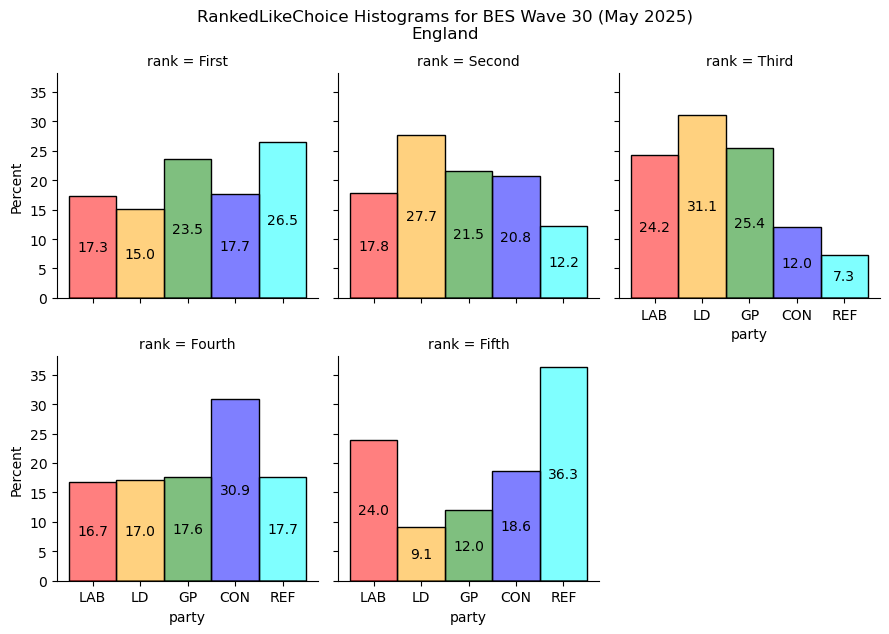

In [164]:
wave = 30
dont_know_protocol = "drop_rows"
drop_below_threshold=None
amalgamate_past_values = False

like_df,like_df_narrow = get_party_rank(wave=wave,dont_know_protocol = dont_know_protocol,drop_below_threshold=drop_below_threshold,like_or_ptv="like",
                                        amalgamate_past_values = amalgamate_past_values,country_level = "England")




pd.crosstab(like_df_narrow["party"],like_df_narrow["rank"],values=like_df_narrow["wt"],aggfunc=sum,normalize='columns')*100

rank,Fifth,First,Fourth,Second,Third
party,,,,,
LAB,19.031421,21.718268,17.784943,17.937462,23.527905
LD,12.557293,15.668504,15.838786,27.100418,28.834998
GP,16.774727,16.154925,20.352458,20.404022,26.313868
CON,20.373913,19.168871,26.091781,21.870233,12.495201
REF,31.262646,27.289431,19.932032,12.687864,8.828027


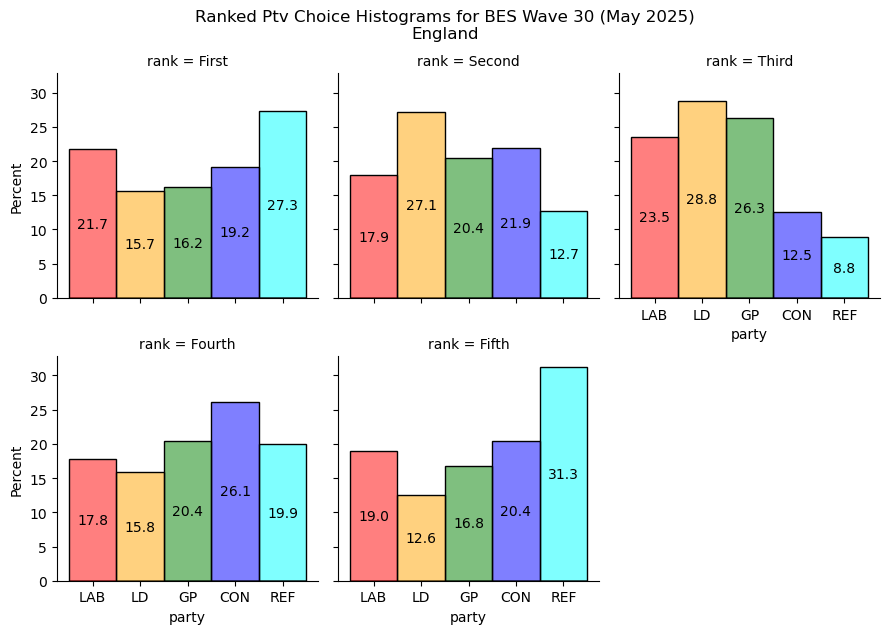

In [166]:
wave = 30
dont_know_protocol = "drop_rows"
drop_below_threshold=None
amalgamate_past_values = False

like_df,like_df_narrow = get_party_rank(wave=wave,dont_know_protocol = dont_know_protocol,drop_below_threshold=drop_below_threshold,like_or_ptv="ptv",
                                        amalgamate_past_values = amalgamate_past_values,country_level = "England")




pd.crosstab(like_df_narrow["party"],like_df_narrow["rank"],values=like_df_narrow["wt"],aggfunc=sum,normalize='columns')*100

rank,Fifth,First,Fourth,Second,Third
party,,,,,
LAB,5.810829,16.502884,8.138634,16.382037,18.020517
LD,2.477208,13.650985,9.394284,24.127281,23.508766
GP,3.561029,21.463096,10.141199,17.811831,18.732591
CON,3.676739,16.792239,16.187100,18.218465,9.586602
REF,6.159112,24.632874,5.616870,10.675385,4.970130
NONE,78.315082,6.957922,50.521913,12.785001,25.181394


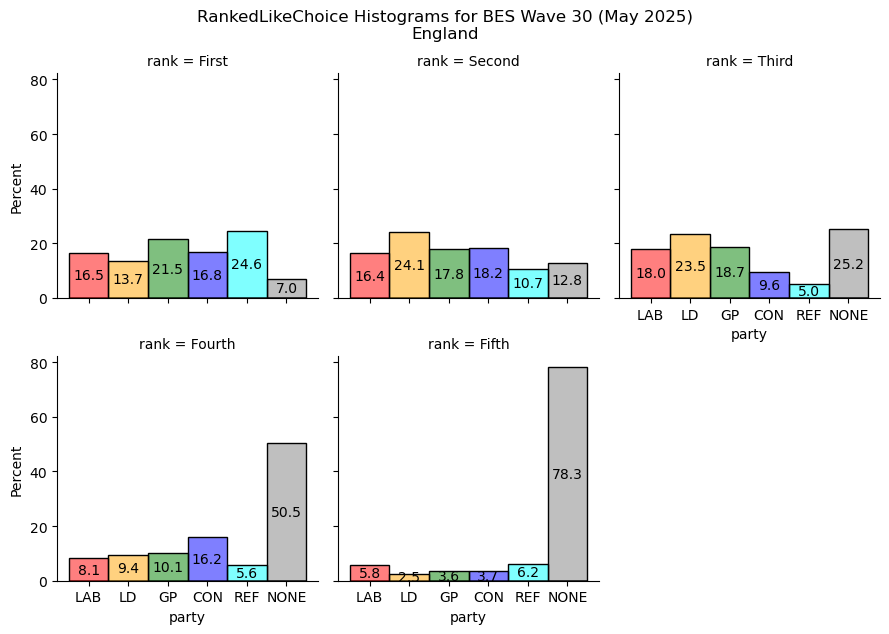

In [163]:
wave = 30
drop_below_threshold=0 # below or equal
dont_know_protocol = "fill_drop_values"
amalgamate_past_values = False

like_df,like_df_narrow = get_party_rank(wave=wave,dont_know_protocol = dont_know_protocol,drop_below_threshold=drop_below_threshold,
                                        amalgamate_past_values = amalgamate_past_values,country_level = "England")




pd.crosstab(like_df_narrow["party"],like_df_narrow["rank"],values=like_df_narrow["wt"],aggfunc=sum,normalize='columns')*100

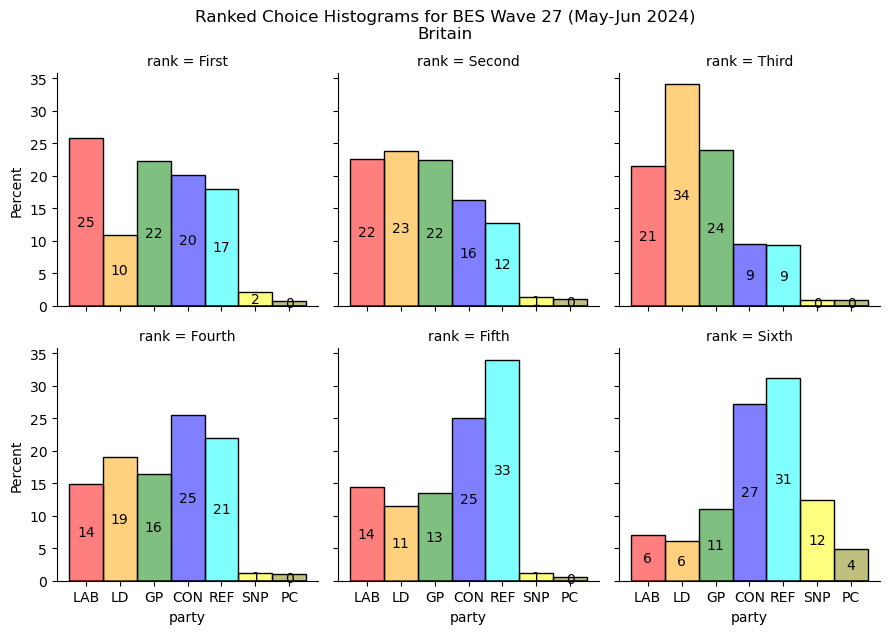

In [466]:
wave = 27
dont_know_protocol = "drop_rows"
amalgamate_past_values = False ### True=highly distortionary, boosts CON first place to 40%!

g=get_party_rank(wave=wave,dont_know_protocol = dont_know_protocol,amalgamate_past_values = amalgamate_past_values)

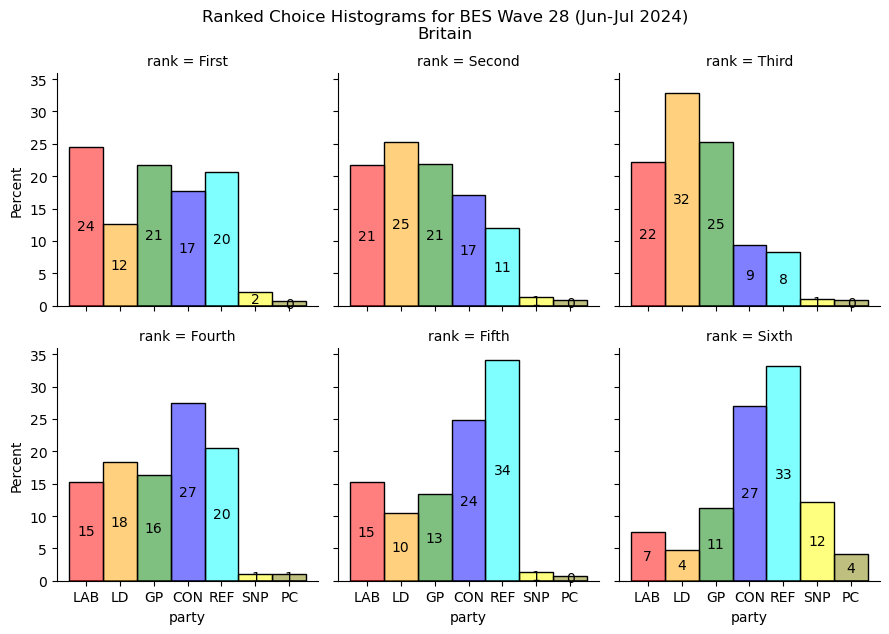

In [467]:
wave = 28
dont_know_protocol = "drop_rows"
amalgamate_past_values = False ### True=highly distortionary, boosts CON first place to 40%!

get_party_rank(wave=wave,dont_know_protocol = dont_know_protocol,amalgamate_past_values = amalgamate_past_values)

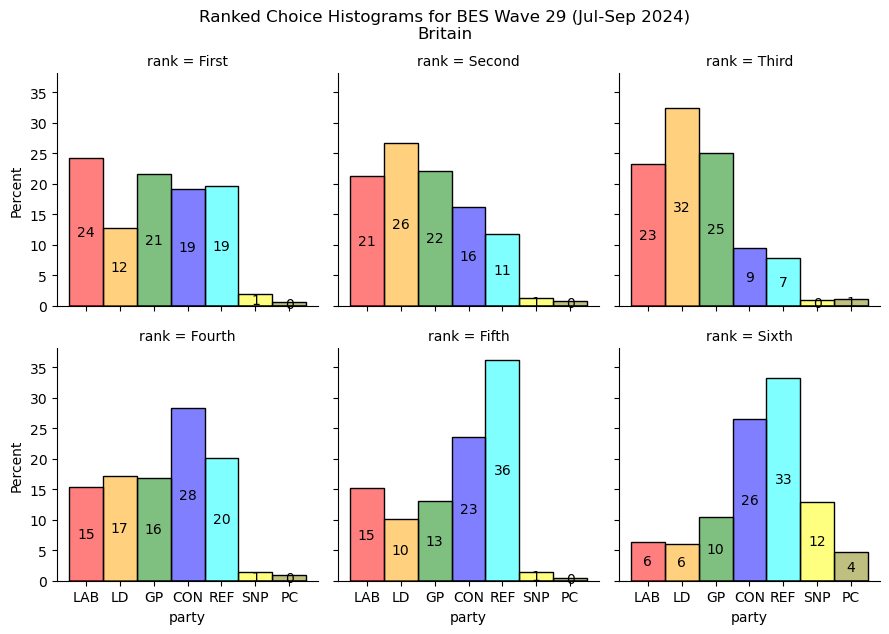

In [468]:
wave = 29
dont_know_protocol = "drop_rows"
amalgamate_past_values = False

get_party_rank(wave=wave,dont_know_protocol = dont_know_protocol,amalgamate_past_values = amalgamate_past_values)

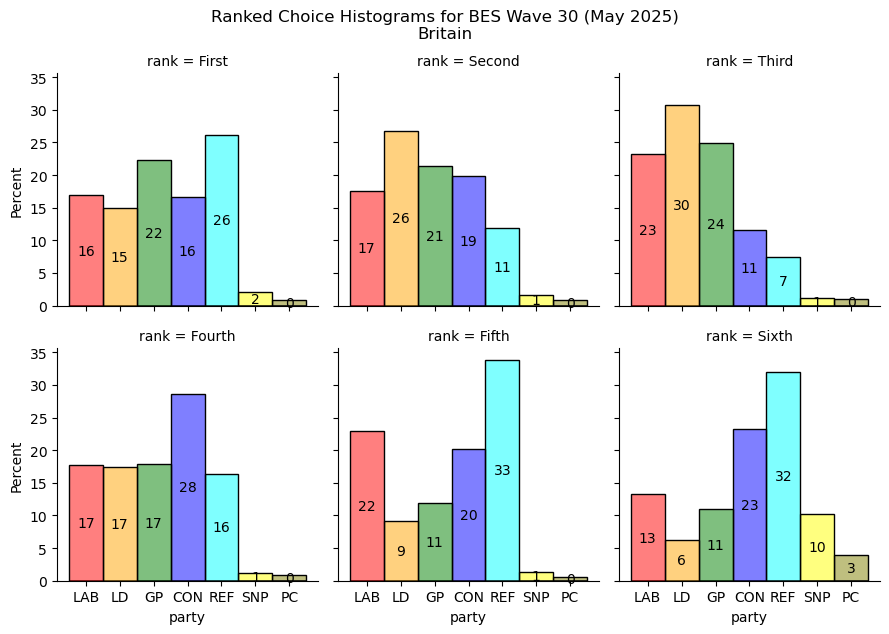

In [470]:
wave = 30
dont_know_protocol = "drop_rows"
amalgamate_past_values = False

get_party_rank(wave=wave,dont_know_protocol = dont_know_protocol,amalgamate_past_values = amalgamate_past_values,
                                        country_level = "Britain")

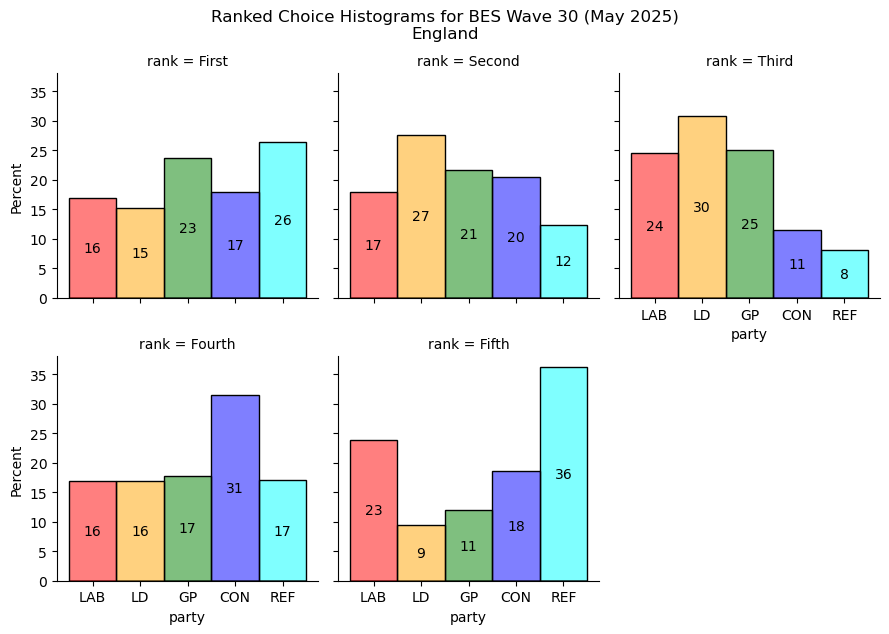

In [460]:
wave = 30
dont_know_protocol = "drop_rows"
amalgamate_past_values = False

like_df,like_df_narrow = get_party_rank(wave=wave,dont_know_protocol = dont_know_protocol,
                                        amalgamate_past_values = amalgamate_past_values,country_level = "England")

In [452]:
like_df.describe()

,likeConW30,likeLabW30,likeLDW30,likeBrexitPartyW30,likeGrnW30,id,wt,max,untied_lead
count,22246.000000,22246.000000,22246.000000,22246.000000,22246.000000,22246.000000,22246.000000,22246.000000,22246.000000
mean,3.233570,3.401106,4.053718,3.244583,4.190191,68196.912883,0.977424,7.277668,0.780904
std,2.927999,3.019811,2.654807,3.619645,2.862554,38695.397786,0.676491,2.011228,0.413643
min,0.000000,0.000000,0.000000,0.000000,0.000000,24.000000,0.111252,0.000000,0.000000
25%,0.000000,0.000000,2.000000,0.000000,2.000000,38359.500000,0.546144,6.000000,1.000000
50%,3.000000,3.000000,5.000000,2.000000,5.000000,70862.500000,0.794501,7.000000,1.000000
75%,6.000000,6.000000,6.000000,6.000000,6.000000,102800.750000,1.192003,9.000000,1.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000,123799.000000,9.421935,10.000000,1.000000


In [458]:
pd.crosstab(like_df_narrow["rank"],like_df_narrow["party"])

party,LAB,LD,GP,CON,REF
rank,,,,,
Fifth,3733,1353,5463,895,10802
First,4646,3286,3818,5085,5411
Fourth,3659,4533,3383,8403,2268
Second,4253,6180,3947,5304,2562
Third,5955,6894,5635,2559,1203


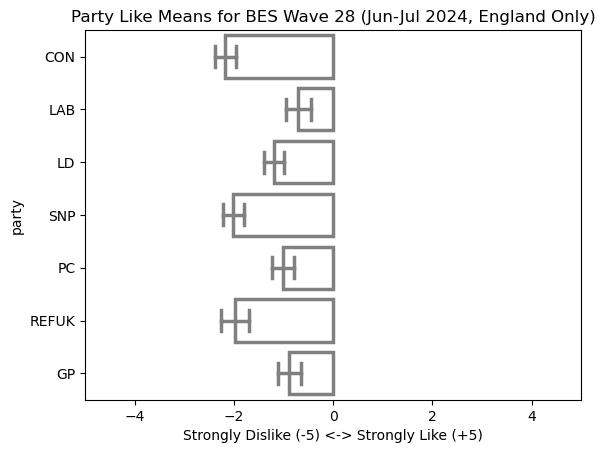

In [ ]:
temp = pd.get_dummies(temp) ### for putting this stuff into xgboost



replace_dict = {'Labour':"LAB", 'Conservative':"CON", 'Brexit Party/Reform UK':"REFUK",
                  'Liberal Democrat':"LD", 'Green Party':"GP",
                  'Scottish National Party (SNP)':np.nan, 'Other':np.nan,
                  'An independent candidate':np.nan, "Don't know":np.nan, 'Plaid Cymru':np.nan,'I would/did not vote':np.nan,}


temp2 = temp[like_list+["wt"]].melt(id_vars = ["id","wt","country"])
temp2.columns = ["id","wt","country","party","rank",]
# sns.barplot(data=temp2,x="rank",weights="wt",y="party")

temp2["rank"] = temp2["rank"]-5
replace_dict = {'Con':"CON", 'Grn':"GP", 'BrexitParty':"REF", 'LD':"LD", 'Lab':"LAB","SNP":"SNP","PC":"PC"}
temp2["party"] = temp2["party"].apply(lambda x: x.split("like")[1].split("W")[0]).replace(replace_dict)

sns.barplot(
    temp2, x="rank", y="party",
    # errorbar=("pi", 50),
    capsize=.4,
    err_kws={"color": ".5", "linewidth": 2.5},
    linewidth=2.5, edgecolor=".5", facecolor=(0, 0, 0, 0), weights="wt",
)
plt.xlim([-5,5]);
plt.title("Party Like Means for BES Wave "+str(wave)+" (Jun-Jul 2024, England Only)");
plt.xlabel("Strongly Dislike (-5) <-> Strongly Like (+5)");

In [223]:
# id:123795 - gives likeCon =0, and no answer for any other party!???

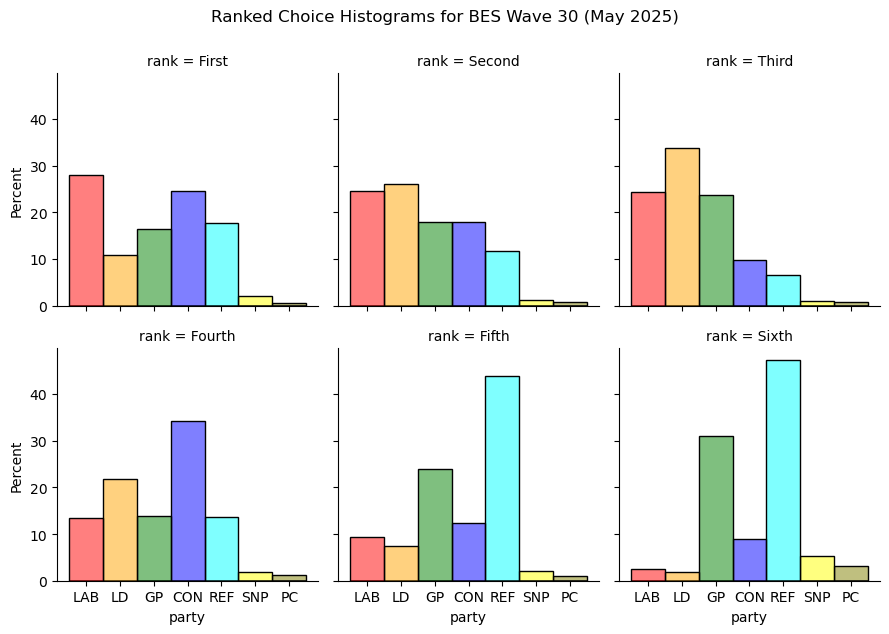

In [20]:
weighted_value_counts(like_df["First"],like_df["wt"],normalize=True,perc=True)

,weighted_sample_percentage,raw_sample_size
First,,
PCW30,0.80,307.0
SNPW30,2.16,759.0
LDW30,13.95,4517.0
LabW30,16.96,5395.0
GrnW30,20.73,6140.0
ConW30,20.76,5641.0
BrexitPartyW30,24.65,7583.0


In [ ]:
like_list = search(BES_Panel,"like(Con|Lab|LD|Grn|BrexitParty)").index
like_df = BES_Panel[like_list]\
    .apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan) + np.random.rand(len(x))*.1  )
rank_list = ["First","Second","Third","Fourth","Fifth"]
like_df[rank_list]=np.nan
like_df[rank_list] = like_df[like_list].apply(lambda x: [y.replace("like","") for y  in x.sort_values(ascending=False).index],axis=1,).apply(lambda x: pd.Series(x)).values
like_df["wt"] = BES_Panel["wt"]

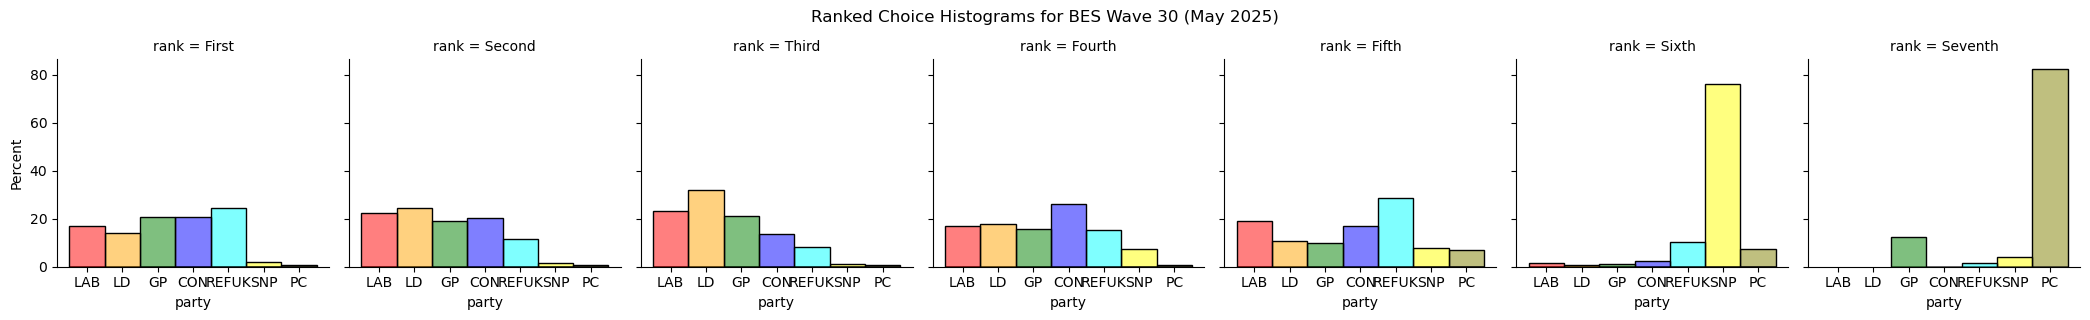

In [26]:
like_df_narrow = like_df[rank_list+["wt"]].melt(id_vars = "wt")
like_df_narrow.columns = ["wt","rank","party"]

replace_dict = {'Con':"CON", 'Grn':"GP", 'BrexitParty':"REFUK", 'LD':"LD", 'Lab':"LAB","SNP":"SNP","PC":"PC"}
palette = {"CON":'blue',"LAB":'red',"REFUK":'cyan',"LD":'orange',"GP":'green',"SNP":'yellow',"PC":'olive'}
like_df_narrow["party"] = like_df_narrow["party"].replace({k+"W"+str(wave):v for k,v in replace_dict.items()})
like_df_narrow["party"] = like_df_narrow["party"].astype('category').cat.reorder_categories(["LAB","LD","GP","CON","REFUK","SNP","PC"])

g = sns.FacetGrid(like_df_narrow, col="rank")
g.map_dataframe(sns.histplot, x="party",weights="wt",stat='percent',palette=palette,hue='party');
g.fig.suptitle("Ranked Choice Histograms for BES Wave 30 (May 2025)",y=1.05);

In [24]:
like_df_narrow["party"].value_counts()

party
ConW30            122372
GrnW30            122372
BrexitPartyW30    122372
LabW30            122372
SNPW30            122372
LDW30             122372
PCW30             122372
Name: count, dtype: int64

In [27]:
# to evaluate various Don't know imputation options we need a measure of the "quality/validity" of the like variables

,likeConW30,likeLabW30,likeLDW30,likeSNPW30,likePCW30,likeBrexitPartyW30,likeGrnW30,First,Second,Third,Fourth,Fifth,Sixth,Seventh,wt
id,,,,,,,,,,,,,,,
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ConW30,LabW30,LDW30,SNPW30,PCW30,BrexitPartyW30,GrnW30,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ConW30,LabW30,LDW30,SNPW30,PCW30,BrexitPartyW30,GrnW30,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ConW30,LabW30,LDW30,SNPW30,PCW30,BrexitPartyW30,GrnW30,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ConW30,LabW30,LDW30,SNPW30,PCW30,BrexitPartyW30,GrnW30,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ConW30,LabW30,LDW30,SNPW30,PCW30,BrexitPartyW30,GrnW30,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123795,0.080247,NaN,NaN,NaN,NaN,NaN,NaN,ConW30,LabW30,LDW30,SNPW30,PCW30,BrexitPartyW30,GrnW30,7.311021
123796,0.042991,2.086442,5.057543,NaN,NaN,0.007767,5.011785,LDW30,GrnW30,LabW30,ConW30,BrexitPartyW30,SNPW30,PCW30,1.545915
123797,10.021752,7.082480,6.050775,NaN,NaN,9.032267,6.022492,ConW30,BrexitPartyW30,LabW30,LDW30,GrnW30,SNPW30,PCW30,1.816420


Amalgamating variables: 
{1: 'likeConW1', 2: 'likeConW2', 3: 'likeConW3', 4: 'likeConW4', 5: 'likeConW5', 6: 'likeConW6', 7: 'likeConW7', 8: 'likeConW8', 9: 'likeConW9', 10: 'likeConW10', 11: 'likeConW11', 12: 'likeConW12', 13: 'likeConW13', 14: 'likeConW14', 15: 'likeConW15', 16: 'likeConW16', 17: 'likeConW17', 18: 'likeConW18', 19: 'likeConW19', 20: 'likeConW20', 21: 'likeConW21', 22: 'likeConW22', 23: 'likeConW23', 24: 'likeConW24', 25: 'likeConW25', 26: 'likeConW26', 27: 'likeConW27', 28: 'likeConW28', 29: 'likeConW29', 30: 'likeConW30'} ['likeConW1', 'likeConW2', 'likeConW3', 'likeConW4', 'likeConW5', 'likeConW6', 'likeConW7', 'likeConW8', 'likeConW9', 'likeConW10', 'likeConW11', 'likeConW12', 'likeConW13', 'likeConW14', 'likeConW15', 'likeConW16', 'likeConW17', 'likeConW18', 'likeConW19', 'likeConW20', 'likeConW21', 'likeConW22', 'likeConW23', 'likeConW24', 'likeConW25', 'likeConW26', 'likeConW27', 'likeConW28', 'likeConW29', 'likeConW30']
Amalgamating variables: 
{1: 'likeLabW1'

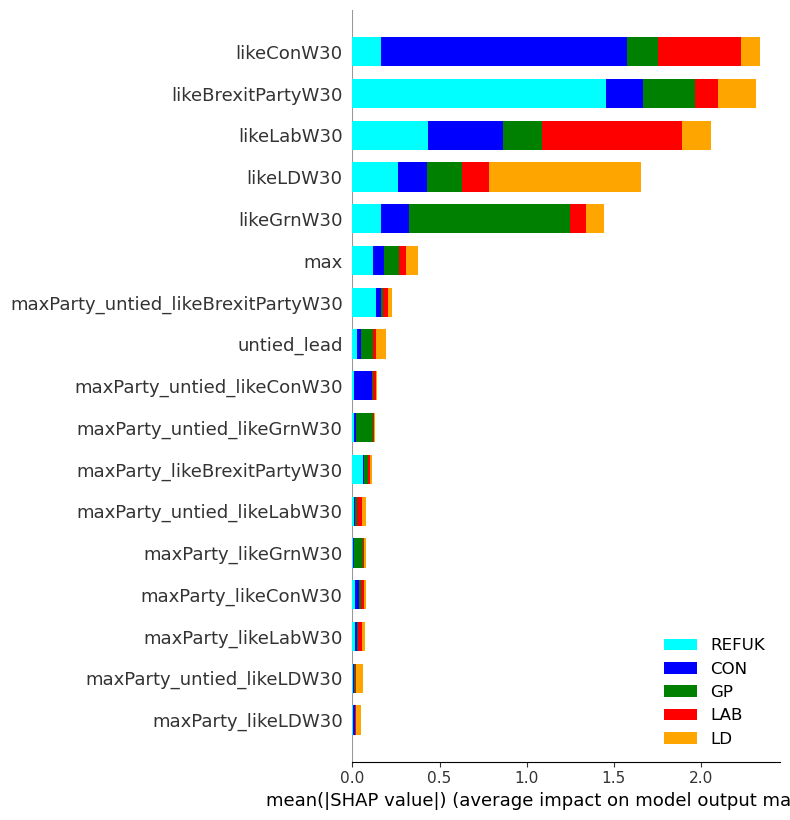

In [208]:
wave = 30
like_list = list( search(BES_Panel,"like(Con|Lab|LD|Grn|BrexitParty)W"+str(wave)).index )
wt_var = search(BES_Panel,"wt_new_W"+str(wave)+"($|_result)").index[0]
target_ser = BES_Panel["p_past_vote_2024"].astype('object').replace(replace_dict).astype('category')
England = BES_Panel["countryW"+str(wave)]=="England"
mask = BES_Panel[wt_var].notnull() & target_ser.notnull() & England
temp = BES_Panel[like_list][mask]

# temp = temp.fillna(5)
# temp = temp.dropna()
for party in like_list:
    temp[party] = amalgamate_waves(BES_Panel[mask],
                                   party.split("W")[0]+"W("+wave_pattern+")$",
                                   low_priority_values = ["Don't know"])
temp[like_list] = temp[like_list].apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan) )


temp["maxParty"] = temp[like_list].apply(lambda x:x + np.random.rand(len(x))*.1 ).idxmax(axis=1).apply(lambda x: np.nan if pd.isna(x) else x)
temp["max"] = temp[like_list].max(axis=1)
#  = 
temp["untied_lead"] = temp[like_list].apply(lambda x: x==temp["max"]).sum(axis=1)==1
# like_df.sum()
# temp["untied_lead"].sum()
temp["maxParty_untied"] = temp["maxParty"]
temp.loc[~temp["untied_lead"],"maxParty_untied"]=np.nan
temp["untied_lead"] = temp["untied_lead"].astype(float)
temp = pd.get_dummies(temp)


replace_dict = {'Labour':"LAB", 'Conservative':"CON", 'Brexit Party/Reform UK':"REFUK",
                  'Liberal Democrat':"LD", 'Green Party':"GP",
                  'Scottish National Party (SNP)':np.nan, 'Other':np.nan,
                  'An independent candidate':np.nan, "Don't know":np.nan, 'Plaid Cymru':np.nan,'I would/did not vote':np.nan,}


name = "GE2025VI"
# temp["GE2024"] = BES_Panel["p_past_vote_2024"].astype('object').replace(replace_dict).astype('category')
temp[name] = target_ser[mask]



print( mask.sum() )
class_names = temp[name].cat.categories
### necessary for xgboost - will only accept categories as numeric ... which is weird
colour_list = [party_colour_dict[x] for x in temp[name].cat.categories]
temp[name] = temp[name].cat.codes.replace(-1,np.nan).astype('category')


party_colour_dict = {"CON":'blue',"LAB":'red',"GP":'green',"LD":'orange',"OTH":'black',"WNV":'darkgrey',"REFUK":'cyan',"UKIP":'purple',"TIG":'pink',
                    "DK":"lightgrey",}
stub_list = []


(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "How did people vote in "+name+"?(England)",
    dataset=temp[mask],
                                                    var_list = [name],var_stub_list = stub_list,verbosity=0,classification_problem=True,
class_names = class_names,colour_list=colour_list,min_features=20)


In [ ]:
# England Only, GE2025VI N = 20802, ACC: 0.68,  F1: 0.68 - no imputation
# England Only, GE2025VI N = 18866, ACC: 0.69,  F1: 0.69 - drop every row with nan
# England Only, GE2025VI N = 20802, ACC: 0.69,  F1: 0.69 - replace nans with 5


# bit insensitive, can we think of a better measure for like variables?

In [210]:
temp.isnull().sum()

likeConW30                             53
likeLabW30                             47
likeLDW30                             226
likeBrexitPartyW30                    139
likeGrnW30                            234
max                                    24
untied_lead                             0
maxParty_likeBrexitPartyW30             0
maxParty_likeConW30                     0
maxParty_likeGrnW30                     0
maxParty_likeLDW30                      0
maxParty_likeLabW30                     0
maxParty_untied_likeBrexitPartyW30      0
maxParty_untied_likeConW30              0
maxParty_untied_likeGrnW30              0
maxParty_untied_likeLDW30               0
maxParty_untied_likeLabW30              0
GE2025VI                                0
dtype: int64

In [212]:
(BES_Panel[like_list][mask]=="Don't know").sum()

likeConW30             232
likeLabW30             226
likeLDW30              950
likeBrexitPartyW30     582
likeGrnW30            1213
dtype: int64

In [177]:
BES_Panel["generalElectionVoteW30"].value_counts().index

CategoricalIndex(['Brexit Party/Reform UK', 'Labour', 'Don't know',
                  'Conservative', 'Liberal Democrat', 'Green Party',
                  'I would/did not vote', 'Scottish National Party (SNP)',
                  'Other', 'Plaid Cymru'],
                 categories=['I would/did not vote', 'Conservative', 'Labour', 'Liberal Democrat', ..., 'Green Party', 'Other', 'Brexit Party/Reform UK', 'Don't know'], ordered=True, dtype='category', name='generalElectionVoteW30')

In [199]:
wave=28
wave_pattern = "|".join([str(x) for x in range(1,wave+1)])
match(BES_Panel,"likeConW("+wave_pattern+")$")



Amalgamating variables: 
{1: 'likeConW1', 2: 'likeConW2', 3: 'likeConW3', 4: 'likeConW4', 5: 'likeConW5', 6: 'likeConW6', 7: 'likeConW7', 8: 'likeConW8', 9: 'likeConW9', 10: 'likeConW10', 11: 'likeConW11', 12: 'likeConW12', 13: 'likeConW13', 14: 'likeConW14', 15: 'likeConW15', 16: 'likeConW16', 17: 'likeConW17', 18: 'likeConW18', 19: 'likeConW19', 20: 'likeConW20', 21: 'likeConW21', 22: 'likeConW22', 23: 'likeConW23', 24: 'likeConW24', 25: 'likeConW25', 26: 'likeConW26', 27: 'likeConW27', 28: 'likeConW28', 29: 'likeConW29', 30: 'likeConW30'} ['likeConW1', 'likeConW2', 'likeConW3', 'likeConW4', 'likeConW5', 'likeConW6', 'likeConW7', 'likeConW8', 'likeConW9', 'likeConW10', 'likeConW11', 'likeConW12', 'likeConW13', 'likeConW14', 'likeConW15', 'likeConW16', 'likeConW17', 'likeConW18', 'likeConW19', 'likeConW20', 'likeConW21', 'likeConW22', 'likeConW23', 'likeConW24', 'likeConW25', 'likeConW26', 'likeConW27', 'likeConW28', 'likeConW29', 'likeConW30']


id
1         Strongly dislike
2                        7
3                        2
4                      NaN
5                        7
                ...       
123795    Strongly dislike
123796    Strongly dislike
123797       Strongly like
123798       Strongly like
123799    Strongly dislike
Name: likeConW1&2&3&4&5&6&7&8&9&10&11&12&13&14&15&16&17&18&19&20&21&22&23&24&25&26&27&28&29&30, Length: 122372, dtype: category
Categories (12, object): ['Strongly dislike', '1', '2', '3', ..., '8', '9', 'Strongly like', 'Don't know']

In [200]:
%%time
likeCon = amalgamate_waves(BES_Panel,"likeConW("+wave_pattern+")$",low_priority_values = ["Don't know"])

Amalgamating variables: 
{1: 'likeConW1', 2: 'likeConW2', 3: 'likeConW3', 4: 'likeConW4', 5: 'likeConW5', 6: 'likeConW6', 7: 'likeConW7', 8: 'likeConW8', 9: 'likeConW9', 10: 'likeConW10', 11: 'likeConW11', 12: 'likeConW12', 13: 'likeConW13', 14: 'likeConW14', 15: 'likeConW15', 16: 'likeConW16', 17: 'likeConW17', 18: 'likeConW18', 19: 'likeConW19', 20: 'likeConW20', 21: 'likeConW21', 22: 'likeConW22', 23: 'likeConW23', 24: 'likeConW24', 25: 'likeConW25', 26: 'likeConW26', 27: 'likeConW27', 28: 'likeConW28', 29: 'likeConW29', 30: 'likeConW30'} ['likeConW1', 'likeConW2', 'likeConW3', 'likeConW4', 'likeConW5', 'likeConW6', 'likeConW7', 'likeConW8', 'likeConW9', 'likeConW10', 'likeConW11', 'likeConW12', 'likeConW13', 'likeConW14', 'likeConW15', 'likeConW16', 'likeConW17', 'likeConW18', 'likeConW19', 'likeConW20', 'likeConW21', 'likeConW22', 'likeConW23', 'likeConW24', 'likeConW25', 'likeConW26', 'likeConW27', 'likeConW28', 'likeConW29', 'likeConW30']
CPU times: total: 32.7 s
Wall time: 33.1

In [207]:
%%time
amalgamate_waves(BES_Panel[mask],party.split("W")[0]+"W("+wave_pattern+")$",low_priority_values = ["Don't know"]).value_counts().sort_index()

Amalgamating variables: 
{1: 'likeGrnW1', 2: 'likeGrnW2', 3: 'likeGrnW3', 4: 'likeGrnW4', 5: 'likeGrnW5', 6: 'likeGrnW6', 7: 'likeGrnW7', 8: 'likeGrnW8', 9: 'likeGrnW9', 10: 'likeGrnW10', 11: 'likeGrnW11', 12: 'likeGrnW12', 13: 'likeGrnW13', 14: 'likeGrnW14', 15: 'likeGrnW15', 16: 'likeGrnW16', 17: 'likeGrnW17', 18: 'likeGrnW18', 19: 'likeGrnW19', 20: 'likeGrnW20', 21: 'likeGrnW21', 22: 'likeGrnW22', 23: 'likeGrnW23', 25: 'likeGrnW25', 26: 'likeGrnW26', 27: 'likeGrnW27', 28: 'likeGrnW28', 29: 'likeGrnW29', 30: 'likeGrnW30'} ['likeGrnW1', 'likeGrnW2', 'likeGrnW3', 'likeGrnW4', 'likeGrnW5', 'likeGrnW6', 'likeGrnW7', 'likeGrnW8', 'likeGrnW9', 'likeGrnW10', 'likeGrnW11', 'likeGrnW12', 'likeGrnW13', 'likeGrnW14', 'likeGrnW15', 'likeGrnW16', 'likeGrnW17', 'likeGrnW18', 'likeGrnW19', 'likeGrnW20', 'likeGrnW21', 'likeGrnW22', 'likeGrnW23', 'likeGrnW25', 'likeGrnW26', 'likeGrnW27', 'likeGrnW28', 'likeGrnW29', 'likeGrnW30']
CPU times: total: 6.94 s
Wall time: 7.1 s


likeGrnW1&2&3&4&5&6&7&8&9&10&11&12&13&14&15&16&17&18&19&20&21&22&23&25&26&27&28&29&30
Strongly dislike    3306
1                   1291
2                   1475
3                   1651
4                   1739
5                   3797
6                   2436
7                   2157
8                   1416
9                    587
Strongly like        713
Don't know             0
Name: count, dtype: int64

In [261]:
likeCon

id
1         Strongly dislike
2                        7
3                        2
4                      NaN
5                        7
                ...       
123795    Strongly dislike
123796    Strongly dislike
123797       Strongly like
123798       Strongly like
123799    Strongly dislike
Name: likeConW1&2&3&4&5&6&7&8&9&10&11&12&13&14&15&16&17&18&19&20&21&22&23&24&25&26&27&28&29&30, Length: 122372, dtype: category
Categories (12, object): ['Strongly dislike', '1', '2', '3', ..., '8', '9', 'Strongly like', 'Don't know']

In [256]:
temp = temp.dropna(subset=like_list)

In [ ]:
#####################################################################################

In [32]:
safest_100 = [
1,23,35,36,38,43,46,48,52,66,71,73,76,84,85,86,87,88,89,90,107,110,111,112,113,139,156,174,181,182,183,187,202,210,212,226,241,248,250,251,256,257,
282,285,288,292,293,300,312,314,316,318,326,327,328,329,332,333,334,335,336,350,351,352,373,386,387,421,422,428,432,436,447,449,450,452,455,464,478,
485,486,488,496,497,519,522,529,537,545,547,548,556,571,575,582,584,586,601,609,631]

remove_15ref = [519,488,485,386,318,226,111,107,35,1]

replace_list = [32,51,78,206,268,343,344,451,482,628]

final_list = [x for x in safest_100 if x not in remove_15ref] + replace_list

final_list_const = [BES_Panel["pcon_may24W30"].cat.categories[x] for x in final_list]

In [10]:
census2024 = pd.read_stata("C:\\Users\\Gamer\\Downloads\\BES-2024-General-Election-results-file-v1.0.dta")

In [11]:
# default order here isn't perfect/determined, but good deault - only new_pcon_codeW10 is out of order
complete_pcon = BES_Panel[search(BES_Panel,"new_pcon_codeW\d+$").index].replace("",np.nan).ffill(axis=1)["new_pcon_codeW30"]
BES_Panel["ONSConstID"] = complete_pcon
BES_Panel = BES_Panel.merge(census2024,on="ONSConstID",how='left')

In [488]:
search(BES_Panel,"new_pcon").tail(50)

new_pconW11         122372
new_pconW12         122372
new_pconW13         122372
new_pconW14         122372
new_pconW17         122372
new_pconW18         122372
new_pconW19         122372
new_pconW20         122372
new_pconW21         122372
new_pconW22         122372
new_pconW23         122372
new_pconW27         122372
new_pconW15         122372
new_pconW16         122372
new_pconW28         122372
new_pconW25         122372
new_pconW26         122372
new_pconW24         122372
new_pconW29         122372
new_pconW30         122372
new_pcon_codeW1     122372
new_pcon_codeW2     122372
new_pcon_codeW4     122372
new_pcon_codeW5     122372
new_pcon_codeW6     122372
new_pcon_codeW7     122372
new_pcon_codeW8     122372
new_pcon_codeW9     122372
new_pcon_codeW10    122372
new_pcon_codeW3     122372
new_pcon_codeW11    122372
new_pcon_codeW12    122372
new_pcon_codeW13    122372
new_pcon_codeW14    122372
new_pcon_codeW17    122372
new_pcon_codeW18    122372
new_pcon_codeW19    122372
n

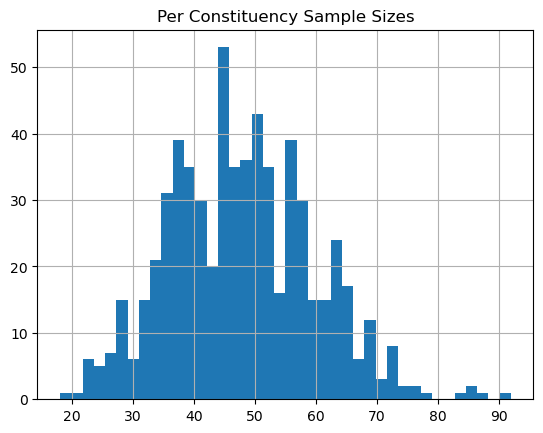

In [576]:
BES_Panel["new_pcon_codeW30"].replace("",np.nan).value_counts().hist(bins=40)
plt.title("Per Constituency Sample Sizes");

In [509]:
BES_Panel["new_pconW30"].value_counts()
# 632 instances != ""

new_pconW30
                                         92055
Ceredigion Preseli                          92
Caithness, Sutherland and Easter Ross       88
Louth and Horncastle                        85
York Central                                85
                                         ...  
Birmingham Perry Barr                       23
Brent East                                  22
Na h-Eileanan an Iar                        22
Leicester East                              20
Knowsley                                    18
Name: count, Length: 633, dtype: int64

In [513]:
BES_Panel["new_pcon_codeW30"].value_counts()

# missing some codes???


BES_Panel["new_pconW30"][BES_Panel["new_pcon_codeW30"]==""].value_counts()

## this looks like a bug!

new_pconW30
                                  92055
South Holland and The Deepings       80
Bridlington and The Wolds            79
Weston-Super-Mare                    63
Name: count, dtype: int64

In [514]:
BES_Panel["new_pconW29"][BES_Panel["new_pcon_codeW29"]==""].value_counts()


# 82 Bridlington and The Wolds
# 506 South Holland and The Deepings
# 606 Weston-super-Mare

new_pconW29
                                  91276
Bridlington and The Wolds            82
South Holland and The Deepings       77
Weston-Super-Mare                    68
Name: count, dtype: int64

In [506]:
BES_Panel["new_pconW30"][BES_Panel["new_pcon_codeW30_num"].isin(safest_100)].value_counts()

new_pconW30
Cardiff North                  76
Dunfermline and Dollar         75
Caerfyrddin                    72
Brecon, Radnor and Cwm Tawe    70
Lincoln                        69
                               ..
Ilford North                   26
Widnes and Halewood            26
Barking                        25
Leicester South                23
Leicester East                 20
Name: count, Length: 115, dtype: int64

In [496]:
BES_Panel["new_pcon_codeW30_num"] = BES_Panel["new_pcon_codeW30"].apply(lambda x: int(x[-3:]) if x!='' else np.nan)

In [499]:
BES_Panel["new_pcon_codeW30_num"][BES_Panel["new_pcon_codeW30_num"].isin(safest_100)].value_counts()

new_pcon_codeW30_num
87.0     188
90.0     174
88.0     164
110.0    147
85.0     145
        ... 
316.0     28
584.0     26
300.0     26
327.0     23
326.0     20
Name: count, Length: 90, dtype: int64

In [500]:
BES_Panel["new_pcon_codeW30_num"].value_counts().sort_index()

new_pcon_codeW30_num
21.0     50
27.0     22
45.0     43
48.0     58
51.0     33
         ..
601.0    56
602.0    39
603.0    57
604.0    85
605.0    67
Name: count, Length: 548, dtype: int64

In [ ]:
##### how does likeGreen / likeLab / gaps and threats vary by constituency?

In [516]:
BES_Panel[["new_pconW30","new_pcon_codeW30"]]

,new_pconW30,new_pcon_codeW30
id,,
1,,
2,,
3,,
4,,
5,,
...,...,...
123795,West Lancashire,E14001577
123796,Birmingham Northfield,E14001097
123797,Portsmouth South,E14001432


In [525]:
search(BES_Panel,"pcon.*W30")

pcon_may24W30            30342
new_pconW30             122372
new_pcon_codeW30        122372
pconW30                 122372
pcon_codeW30            122372
new_pcon_codeW30_num     30095
dtype: int64

In [530]:
BES_Panel["pcon_may24W30"].cat.categories[606]

'Weston-Super-Mare'

Index(['NOT in a Parliamentary Constituency', 'Aberafan Maesteg',
       'Aberdeen North', 'Aberdeen South',
       'Aberdeenshire North and Moray East', 'Airdrie and Shotts', 'Aldershot',
       'Aldridge-Brownhills', 'Alloa and Grangemouth',
       'Altrincham and Sale West',
       ...
       'Worsley and Eccles', 'Worthing West', 'Wrexham', 'Wycombe',
       'Wyre Forest', 'Wythenshawe and Sale East', 'Yeovil', 'Ynys Mon',
       'York Central', 'York Outer'],
      dtype='object', length=633)

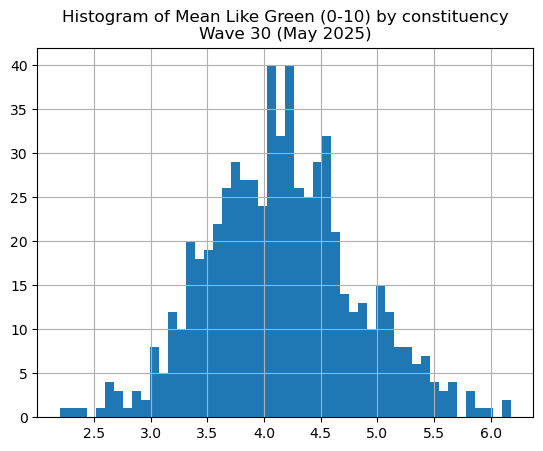

In [630]:
BES_Panel["likeGrnW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan).groupby( BES_Panel["new_pconW30"].replace("",np.nan) ).mean().hist(bins=50);
plt.title("Histogram of Mean Like Green (0-10) by constituency\nWave 30 (May 2025)");

In [629]:
BES_Panel["likeGrnW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan).mean()

4.14336569579288

In [627]:
BES_Panel["likeGrnW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan).groupby( BES_Panel["new_pconW30"].replace("",np.nan) ).mean().sort_values().tail(50)

new_pconW30
Bristol East                     5.125000
Truro and Falmouth               5.125000
Peckham                          5.129032
Nottingham South                 5.148148
Waveney Valley                   5.152174
Reading Central                  5.163636
Sheffield Hallam                 5.172414
Ceredigion Preseli               5.191011
Birkenhead                       5.191489
Slough                           5.200000
Edmonton and Winchmore Hill      5.206897
Glasgow North East               5.225000
Walthamstow                      5.232558
South Suffolk                    5.236842
Bermondsey and Old Southwark     5.259259
Hampstead and Highgate           5.259259
Bethnal Green and Stepney        5.263158
Cheltenham                       5.269231
Battersea                        5.297297
Liverpool Riverside              5.307692
Oxford East                      5.309524
Dulwich and West Norwood         5.314286
Smethwick                        5.357143
Islington North       

In [37]:
search(BES_Panel,"ONS")

responsibleDebtConservativesW1     30190
responsibleDebtLiberalDemsW1       30190
responsibleDebtLabourW1            30190
responsibleDebtUKBanksW1           30190
responsibleDebtGlobalBanksW1       30190
                                   ...  
big_five_conscientiousness         25422
ONSConstID                        120738
ConstituencyName                  120738
ConstituencyType                  120738
c21IndustryConstruction           120738
Length: 696, dtype: int64

In [43]:
split_var = "ONSConstID"

const_grn_like = BES_Panel["likeGrnW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan).groupby( BES_Panel[split_var].replace("",np.nan) ).mean()
const_grn_vote = BES_Panel["Green24"].groupby( BES_Panel[split_var].replace("",np.nan) ).mean()

const_grn_like.corr(const_grn_vote)
# const_grn_like

0.532295797491146

In [44]:
const_lab_like = BES_Panel["likeLabW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan).groupby( BES_Panel[split_var].replace("",np.nan) ).mean()
const_lab_vote = BES_Panel["Lab24"].groupby( BES_Panel[split_var].replace("",np.nan) ).mean()
const_lab_like.corr(const_lab_vote)

0.36788294854467163

In [45]:
const_ld_like = BES_Panel["likeLDW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan).groupby( BES_Panel[split_var].replace("",np.nan) ).mean()
const_ld_vote = BES_Panel["LD24"].groupby( BES_Panel[split_var].replace("",np.nan) ).mean()
const_ld_like.corr(const_ld_vote)

0.4134750165067029

In [46]:
const_con_like = BES_Panel["likeConW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan).groupby( BES_Panel[split_var].replace("",np.nan) ).mean()
const_con_vote = BES_Panel["Con24"].groupby( BES_Panel[split_var].replace("",np.nan) ).mean()
const_con_like.corr(const_con_vote)

0.7069578150477099

In [47]:
const_ref_like = BES_Panel["likeBrexitPartyW30"].replace("Don't know",np.nan).replace(-1,np.nan).cat.codes.groupby( BES_Panel[split_var].replace("",np.nan) ).mean()
const_ref_vote = BES_Panel["RUK24"].groupby( BES_Panel[split_var].replace("",np.nan) ).mean()
const_ref_like.corr(const_ref_vote)

0.5971201487781063

In [ ]:
# There’s around a 1-point gap between Greens and Labour in the country in BES 30
# average scores. What is the gap in these seats as a whole and individually? If you
# wanted to make histograms for the distribution of likeability gaps in each
# constituency, then that would be wonderful, but I understand you have a life to live.
# I’ll leave it up to you if you find this interesting and how you’d like to approach it to
# make it most fun and rewarding for yourself. I do now have the ear of the Green
# Party CEO, and this work could transform their ambitions if it yields anything interesting.

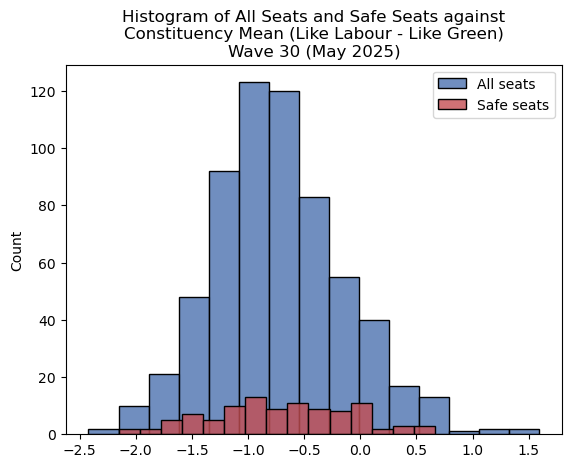

In [49]:
const_lab_green_gap = (BES_Panel["likeLabW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)\
                       -BES_Panel["likeGrnW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan))\
    .groupby( BES_Panel[split_var].replace("",np.nan) ).mean()

safe_seat_mask = BES_Panel["new_pconW30"].replace("",np.nan).isin(final_list_const)

const_lab_green_gap_ss = (BES_Panel["likeLabW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)\
                          -BES_Panel["likeGrnW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan))[safe_seat_mask]\
    .groupby( BES_Panel[split_var][safe_seat_mask].replace("",np.nan) ).mean()

sns.histplot(const_lab_green_gap,alpha=.8,label="All seats",color='b',bins=15);
sns.histplot(const_lab_green_gap_ss,alpha=.8,label="Safe seats",color='r',bins=15);
plt.legend();
plt.title("Histogram of All Seats and Safe Seats against\nConstituency Mean (Like Labour - Like Green)\nWave 30 (May 2025)");

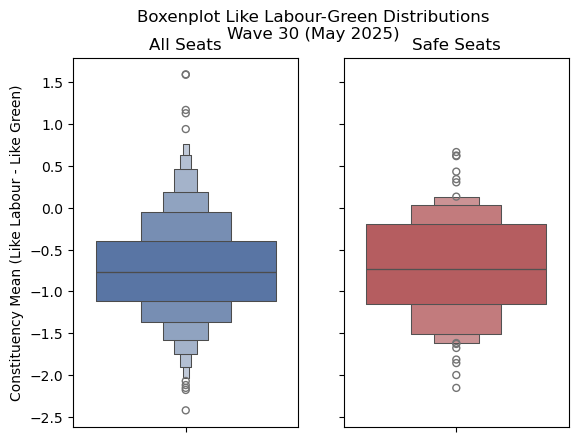

In [50]:
f, (ax1, ax2) = plt.subplots(1,2,sharey='all');
sns.boxenplot(const_lab_green_gap,label="all seats",color='b',ax=ax1);
sns.boxenplot(const_lab_green_gap_ss,label="safe seats",color='r',ax=ax2);
ax1.set_title("All Seats");
ax2.set_title("Safe Seats");
ax1.set_ylabel("Constituency Mean (Like Labour - Like Green)");
plt.suptitle("Boxenplot Like Labour-Green Distributions\nWave 30 (May 2025)");

In [1]:
import os
import geopandas as gpd

In [51]:
# C:\Users\Gamer\Downloads\Westminster_Parliamentary_Constituencies_July_2024_Boundaries_UK_BFC_8322311767861589132

In [4]:
shapefile = "C:\\Users\\Gamer\\Downloads\\Westminster_Parliamentary_Constituencies_July_2024_Boundaries_UK_BFC_8322311767861589132\\PCON_JULY_2024_UK_BFC.shp"
map_df = gpd.read_file(shapefile)

In [16]:
census2024["ONSConstID"].isin(map_df["PCON24CD"]).sum()
map_df["PCON24CD"].isin(census2024["ONSConstID"]).sum()

632

In [20]:
map_df = map_df.set_index("PCON24CD").join(census2024.set_index("ONSConstID"),how='left')

In [52]:
const_lab_green_gap

ONSConstID
E14001063   -0.891892
E14001064   -0.928571
E14001065   -0.487179
E14001066   -1.066667
E14001067   -1.361111
               ...   
W07000108    0.117647
W07000109   -0.183333
W07000110   -0.527273
W07000111   -0.256410
W07000112   -0.609756
Length: 629, dtype: float64

In [72]:
# map_df["GreenLike"] = 
# const_grn_like.loc[map_df.index]


In [78]:
const_grn_like.name='LikeGreen'
map_df = map_df.join(const_grn_like)

const_lab_like.name='LikeLab'
map_df = map_df.join(const_lab_like)

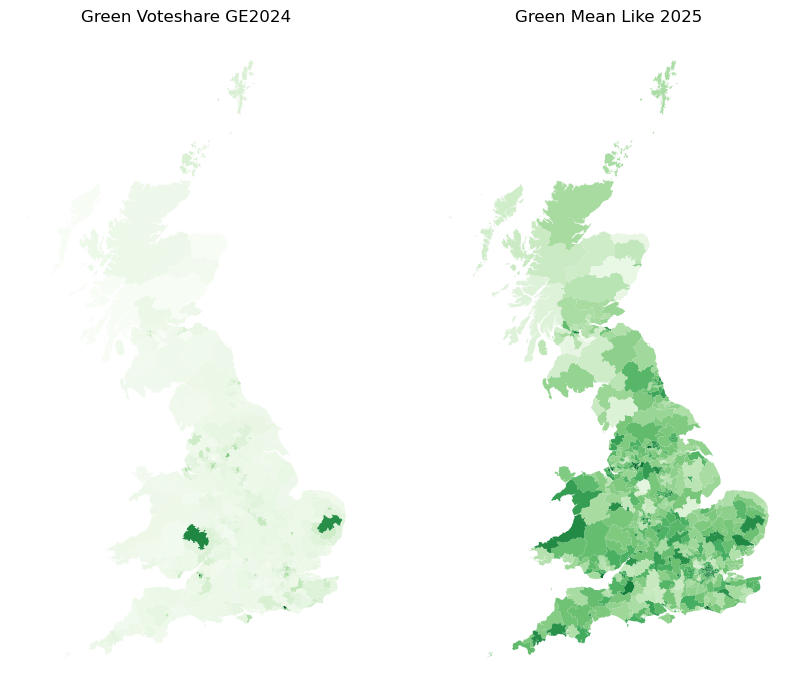

In [86]:
f, [ax1,ax2] = plt.subplots(1,2, figsize=(10, 10))
ax = map_df.plot(column="Green24",cmap='Greens',ax=ax1);
ax.axis("off");
ax.set_title("Green Voteshare GE2024");
ax = map_df.plot(column="LikeGreen",cmap='Greens',ax=ax2);
ax.axis("off");
ax.set_title("Green Mean Like 2025");

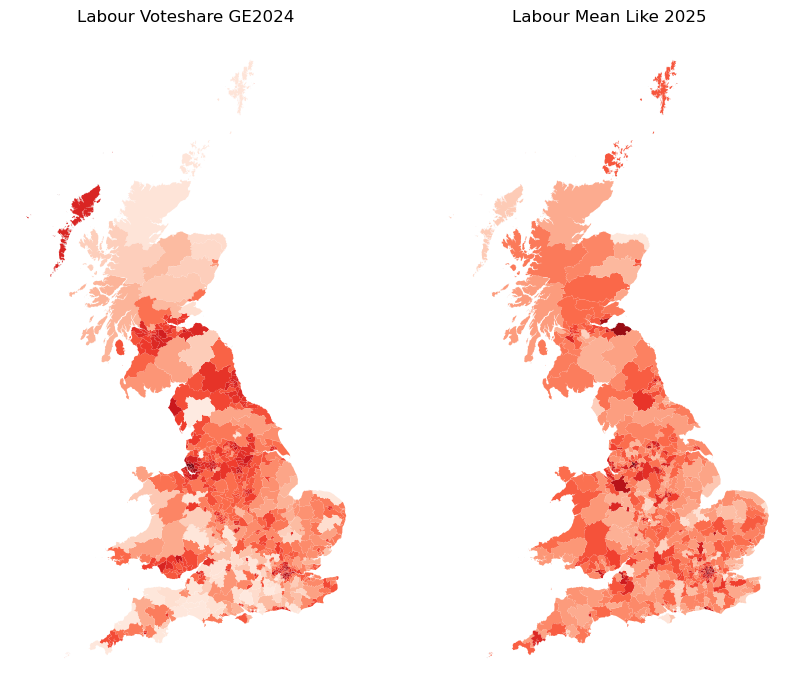

In [85]:
f, [ax1,ax2] = plt.subplots(1,2, figsize=(10, 10))
ax = map_df.plot(column="Lab24",cmap='Reds',ax=ax1);
ax.axis("off");
ax.set_title("Labour Voteshare GE2024");
ax = map_df.plot(column="LikeLab",cmap='Reds',ax=ax2);
ax.axis("off");
ax.set_title("Labour Mean Like 2025");

In [99]:
map_df.drop("LikeLabGreen",inplace=True,axis=1)
map_df["LabGreen24"] = map_df["Green24"]-map_df["Lab24"]
# const_lab_green_gap.name='LikeLabGreen'
# const_lab_green_gap = -const_lab_green_gap
# map_df = map_df.join(const_lab_green_gap)

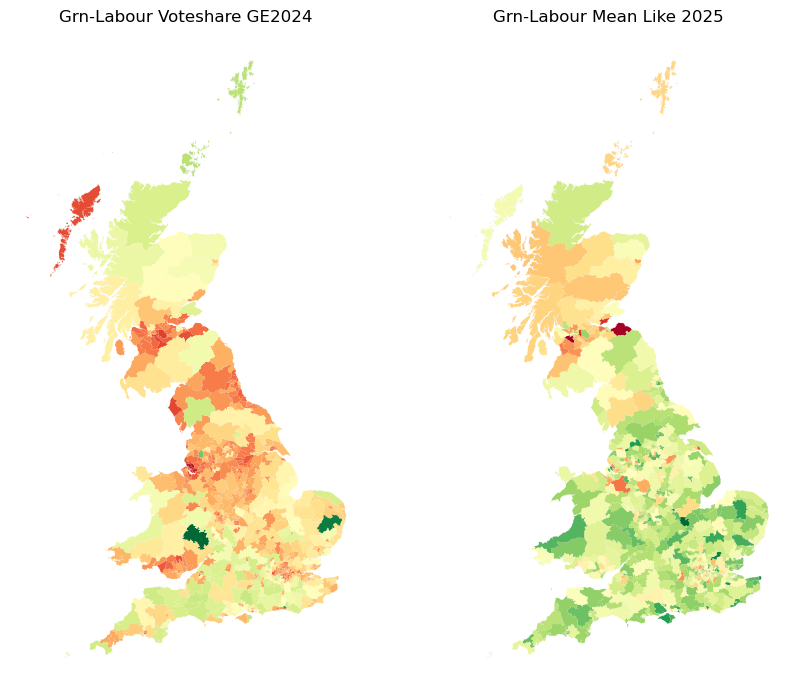

In [107]:
f, [ax1,ax2] = plt.subplots(1,2, figsize=(10, 10))
ax = map_df.plot(column="LabGreen24",cmap='RdYlGn',ax=ax1);
ax.axis("off");
ax.set_title("Grn-Labour Voteshare GE2024");
ax = map_df.plot(column="LikeLabGreen",cmap='RdYlGn',ax=ax2);
ax.axis("off");
ax.set_title("Grn-Labour Mean Like 2025");